In [11]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

In [22]:
file_path = "../datasets/image_v15.hdf5"

with h5py.File(file_path, "r") as f:
    print("High level keys: ", f.keys())
    demos = sorted(f["data"].keys())
    print("Number of demonstrations:", len(demos))

    demo = f["data"][demos[199]]
    print("Available observations:", list(demo["obs"].keys()))

    # Load camera images into memory before closing the file
    agentview_images = demo["obs"]["agentview_image"][:]
    eye_in_hand_images = demo["obs"]["robot0_eye_in_hand_image"][:]

print("Image shape:", agentview_images.shape)
print("Image dtype:", agentview_images.dtype)



High level keys:  <KeysViewHDF5 ['data', 'mask']>
Number of demonstrations: 200
Available observations: ['agentview_image', 'object', 'robot0_eef_pos', 'robot0_eef_quat', 'robot0_eef_quat_site', 'robot0_eye_in_hand_image', 'robot0_gripper_qpos', 'robot0_gripper_qvel', 'robot0_joint_acc', 'robot0_joint_pos', 'robot0_joint_pos_cos', 'robot0_joint_pos_sin', 'robot0_joint_vel']
Image shape: (46, 84, 84, 3)
Image dtype: uint8


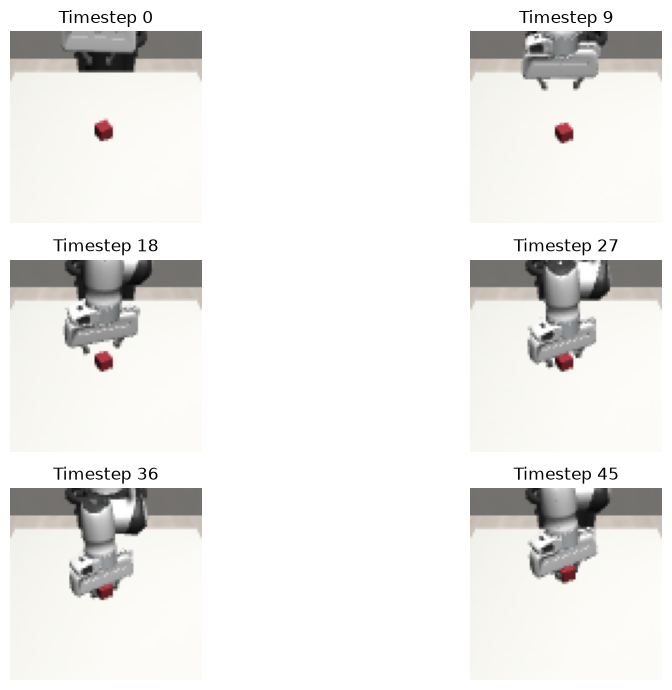

In [23]:
indices = np.linspace(0, len(agentview_images) - 1, 6, dtype=int)

fig, axes = plt.subplots(3, 2, figsize=(12, 7))

for ax, idx in zip(axes.flat, indices):
    ax.imshow(agentview_images[idx])
    ax.set_title(f"Timestep {idx}")
    ax.axis("off")

plt.tight_layout()
plt.show()

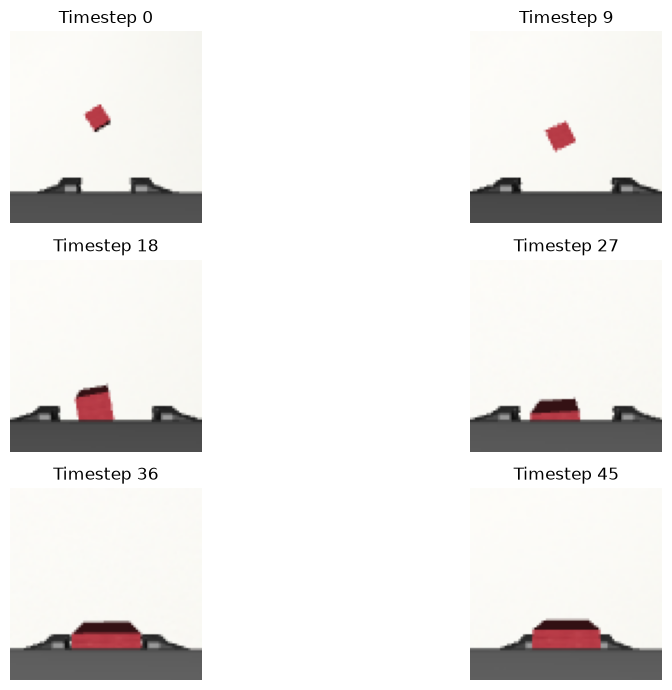

In [24]:
indices = np.linspace(0, len(eye_in_hand_images) - 1, 6, dtype=int)

fig, axes = plt.subplots(3, 2, figsize=(12, 7))

for ax, idx in zip(axes.flat, indices):
    ax.imshow(eye_in_hand_images[idx])
    ax.set_title(f"Timestep {idx}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [51]:
from dataset import RoboMimicDataset

data = RoboMimicDataset(file_path)
print(len(data))
print(data[0].keys())

9666
dict_keys(['observation', 'action_chunk', 'action_mask'])


In [52]:
print(data[0]["observation"].keys())
print(data[0]["observation"]["agent_image"].shape)
print(data[0]["observation"]["wrist_image"].shape)
print(data[0]["observation"]["proprio"].shape)


dict_keys(['agent_image', 'wrist_image', 'proprio'])
torch.Size([3, 84, 84])
torch.Size([3, 84, 84])
torch.Size([9])


In [54]:
print(data[58]["action_chunk"])
print(data[58]["action_mask"])



tensor([[ 0.2640, -0.0950,  1.0000,  0.0070,  0.1418,  0.0412,  1.0000],
        [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  0.0000,  0.000

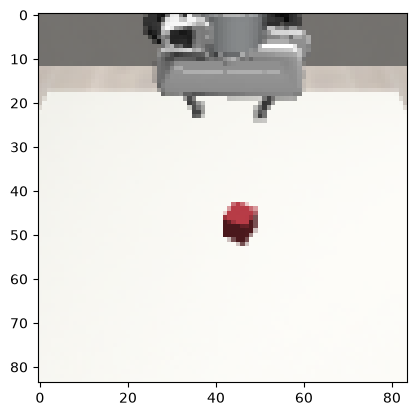

In [58]:
img = data[10]["observation"]["agent_image"]
plt.imshow(img.permute(1,2,0))

